# Lab L3-2：B 線換了相機——CycleGAN 沒有成對影像也能轉換（D3-2）

**需求單 #D3-2**（虛構公司：曜嶼電子，製造品保部 B 線）：B 線換了相機，A 線訓練的瑕疵模型在 B 線一直誤報（過殺）。
沒有「同一片板子在兩條線各拍一張」的成對影像。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| 1 | 準備資料：VisA PCB1 當 A 線；用程式做出 B 線的相機差異（偏暖、偏亮、對比、雜訊） | A／B 對照圖 |
| 2 | 訓練 A 線的 AE 檢測器（D2-1 的做法），量它在 B 線的過殺 | 過殺：A 線 vs B 線 |
| 3 | 訓練 CycleGAN：B → A、A → B 兩個生成器、兩個鑑別器 | 每個 epoch 的轉換圖 |
| 4 | 把 B 線影像轉成「A 線風格」再檢測：過殺有沒有下降？瑕疵有沒有被抹掉？ | 對照表 |

> 狀態：尚未在 Colab T4 實跑（見 `research/lab-runs.md`）。B 線是**合成**的相機差異，不是真的第二條產線。

In [19]:
# 第 1 格：環境
%pip install -q -U scikit-learn
import torch, os, glob, random, platform, time
import numpy as np
import matplotlib.pyplot as plt
print("torch", torch.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
SIZE = 64           # CycleGAN 用小圖，T4 上幾分鐘就能看到效果
EPOCHS_AE = 20      # 沒有 GPU：改成 2
EPOCHS_GAN = 20     # 沒有 GPU：改成 1

torch 2.14.1+cu130 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 14.5 / 15.6 GB


## 1. 資料：A 線＝VisA PCB1；B 線＝同樣的板子類型，換了一台相機
和 D2-1 一樣下載 VisA（約 1.9 GB），只解壓 `pcb1`。已經有資料夾就會跳過下載。

**切分**（每一張板子只出現在一個地方：A 線和 B 線拍的是**不同的板子** → 沒有成對影像）

In [20]:
VISA_URL = "https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"
CATEGORY = "pcb1"
DATA_DIR = f"data/download/visa/{CATEGORY}"   # 講師若放在雲端硬碟，改成那個資料夾

if not os.path.isdir(DATA_DIR):
    os.makedirs("data/download/visa", exist_ok=True)
    if not os.path.exists("data/download/visa/VisA.tar"):
        os.system(f"wget -q -O data/download/visa/VisA.tar {VISA_URL}")
    os.system(f"tar -xf data/download/visa/VisA.tar -C data/download/visa --wildcards '{CATEGORY}/*'")
normal = sorted(glob.glob(f"{DATA_DIR}/**/Normal/*.*", recursive=True))
anomaly = sorted(p for p in glob.glob(f"{DATA_DIR}/**/Anomaly/*.*", recursive=True) if "/Masks/" not in p.replace("\\", "/"))
random.shuffle(normal)
split = {"A_train": normal[:400], "B_train": normal[400:800], "A_val": normal[800:900], "test_ok": normal[900:]}
for k, v in split.items():
    print(f"{k:8s} {len(v):4d} 張良品")
print(f"anomaly  {len(anomaly):4d} 張不良品（附瑕疵遮罩）")

A_train   400 張良品
B_train   400 張良品
A_val     100 張良品
test_ok   104 張良品
anomaly   100 張不良品（附瑕疵遮罩）


In [21]:
from PIL import Image
from torchvision.transforms.functional import to_tensor

def load(paths):
    return torch.stack([to_tensor(Image.open(p).convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)) for p in paths])

def mask_path(p):
    p = p.replace("\\", "/")
    return os.path.splitext(p.replace("/Images/Anomaly/", "/Masks/Anomaly/"))[0] + ".png"

t0 = time.time()
X = {k: load(v) for k, v in split.items()}
X["bad"] = load(anomaly)
M_bad = torch.stack([to_tensor(Image.open(mask_path(p)).convert("L").resize((SIZE, SIZE), Image.NEAREST)) for p in anomaly])[:, 0] > 0
print(f"讀取完成 {time.time()-t0:.0f}s | 一張圖", tuple(X["A_train"][0].shape), "| 瑕疵平均佔", f"{M_bad.float().mean():.1%}", "的像素")

讀取完成 17s | 一張圖 (3, 64, 64) | 瑕疵平均佔 0.9% 的像素


**B 線相機**：比 A 線偏暖（紅多藍少）、偏亮、對比強一點、雜訊多一點。
這是我們**自己做出來的**差異，所以知道答案；真實產線的差異要先拍照比對才知道。

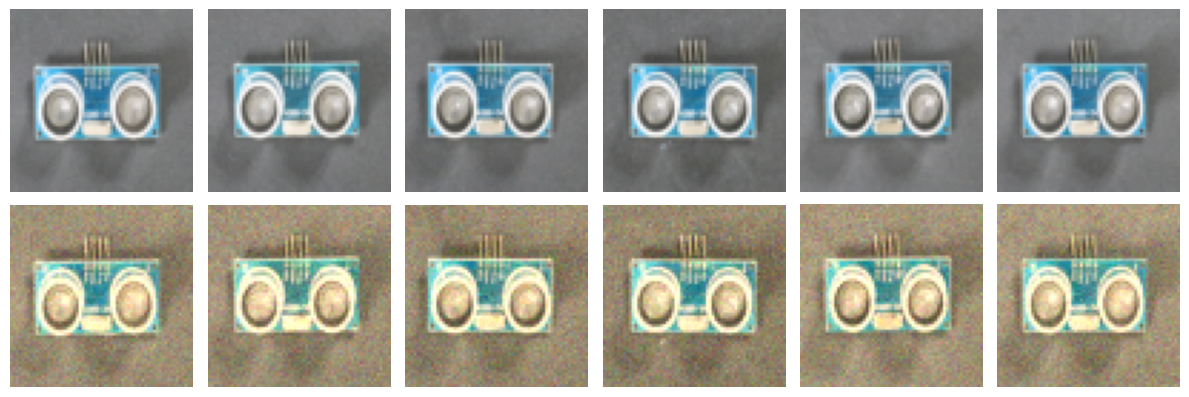

In [22]:
import torch.nn.functional as F

def to_line_b(x, seed=1):
    gen = torch.Generator().manual_seed(seed)
    tint = torch.tensor([1.12, 1.00, 0.80]).view(1, 3, 1, 1)        # 偏暖：紅 ×1.12、藍 ×0.80
    y = (x * tint).clamp(0, 1) ** 0.8                                # 偏亮（gamma 0.8）
    y = (y - 0.5) * 1.2 + 0.5                                        # 對比強一點
    y = y + 0.04 * torch.randn(y.shape, generator=gen)               # 感光雜訊多一點
    return y.clamp(0, 1)

X["B_train"] = to_line_b(X["B_train"], seed=1)
X["test_ok_B"] = to_line_b(X["test_ok"], seed=2)
X["bad_B"] = to_line_b(X["bad"], seed=3)

fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
for i in range(6):
    ax[0, i].imshow(X["test_ok"][i].permute(1, 2, 0)); ax[1, i].imshow(X["test_ok_B"][i].permute(1, 2, 0))
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.savefig("line_a_vs_b.png", dpi=120); plt.show()       # 上排 A 線、下排 B 線

## 2. A 線的檢測器：D2-1 的卷積 AE
只用 A 線良品訓練（加上旋轉 180°：PCB1 良品多半倒著拍，見 D2-1）。
**門檻**：A 線驗證良品分數的第 95 百分位 → 在 A 線上，設計成「每 100 片好板子約 5 片誤報」。

In [23]:
import torch.nn as nn
from sklearn.metrics import roc_auc_score

def down(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.LeakyReLU(0.2))
def up(cin, cout):
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.ReLU())

ae = nn.Sequential(down(3, 32), down(32, 64), down(64, 128), up(128, 64), up(64, 32),
                   nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid()).to(device)
xa = torch.cat([X["A_train"], X["A_train"].flip(-2, -1)])
opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
t0 = time.time()
for epoch in range(1, EPOCHS_AE + 1):
    ae.train()
    for i in torch.randperm(len(xa)).split(32):
        xb = xa[i].to(device)
        loss = F.mse_loss(ae(xb), xb)
        opt.zero_grad(); loss.backward(); opt.step()
print(f"AE 訓練完成：{EPOCHS_AE} epochs，{time.time()-t0:.0f}s，最後 loss {loss.item():.5f}")

@torch.no_grad()
def err_map(x):
    ae.eval()
    out = []
    for xb in x.split(64):
        xb = xb.to(device); out.append(((xb - ae(xb)) ** 2).mean(1).cpu())
    return torch.cat(out)                                    # [N, H, W]

def score(x):
    m = err_map(x).flatten(1)
    return m.topk(max(1, m.shape[1] // 100), dim=1).values.mean(1)   # 誤差最大 1% 的平均（D2-1）

THR = torch.quantile(score(X["A_val"]), 0.95).item()
print(f"門檻（A 線驗證良品第 95 百分位）＝ {THR:.5f}")

AE 訓練完成：20 epochs，2s，最後 loss 0.00061
門檻（A 線驗證良品第 95 百分位）＝ 0.01687


In [24]:
def report(name, ok, bad):
    s_ok, s_bad = score(ok), score(bad)
    over = (s_ok > THR).float().mean().item()                    # 過殺：好板子被判壞
    miss = (s_bad <= THR).float().mean().item()
    auroc = roc_auc_score([0] * len(s_ok) + [1] * len(s_bad), torch.cat([s_ok, s_bad]).numpy())
    print(f"{name:28s} 過殺 {over:6.1%} | 漏檢 {miss:6.1%} | AUROC {auroc:.3f}")
    return dict(name=name, over=over, miss=miss, auroc=auroc)

rows = [report("A 線（原本的相機）", X["test_ok"], X["bad"]),
        report("B 線（新相機，直接檢測）", X["test_ok_B"], X["bad_B"])]

A 線（原本的相機）                   過殺   1.9% | 漏檢  88.0% | AUROC 0.863
B 線（新相機，直接檢測）                過殺 100.0% | 漏檢   0.0% | AUROC 0.848


## 3. CycleGAN：兩個生成器、兩個鑑別器
- **G：B → A**（把 B 線影像轉成 A 線風格）；**F：A → B**
- **D_A**：這張是真的 A 線影像嗎？**D_B**：這張是真的 B 線影像嗎？
- D 是 **PatchGAN**：輸出不是一個分數，而是一張「每一小塊像不像」的分數圖

**練習**：投影片「練習：哪一項損失擋住哪一種錯？」最後一列問 128 × 128 輸入時 D 的輸出 shape；先自己算，再把下一格的 `t` 改成 128 × 128 驗證。

In [25]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.body = nn.Sequential(nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c), nn.ReLU(),
                                  nn.ReflectionPad2d(1), nn.Conv2d(c, c, 3), nn.InstanceNorm2d(c))
    def forward(self, x):
        return x + self.body(x)                     # 殘差：只學「要改多少」

def generator(c=32, n_res=4):
    return nn.Sequential(
        nn.ReflectionPad2d(3), nn.Conv2d(3, c, 7), nn.InstanceNorm2d(c), nn.ReLU(),
        nn.Conv2d(c, 2 * c, 3, 2, 1), nn.InstanceNorm2d(2 * c), nn.ReLU(),            # 64 → 32
        nn.Conv2d(2 * c, 4 * c, 3, 2, 1), nn.InstanceNorm2d(4 * c), nn.ReLU(),        # 32 → 16
        *[ResBlock(4 * c) for _ in range(n_res)],
        nn.ConvTranspose2d(4 * c, 2 * c, 3, 2, 1, output_padding=1), nn.InstanceNorm2d(2 * c), nn.ReLU(),
        nn.ConvTranspose2d(2 * c, c, 3, 2, 1, output_padding=1), nn.InstanceNorm2d(c), nn.ReLU(),
        nn.ReflectionPad2d(3), nn.Conv2d(c, 3, 7), nn.Tanh())                         # −1～1

def patch_d(c=64):
    return nn.Sequential(
        nn.Conv2d(3, c, 4, 2, 1), nn.LeakyReLU(0.2),                                   # 64 → 32
        nn.Conv2d(c, 2 * c, 4, 2, 1), nn.InstanceNorm2d(2 * c), nn.LeakyReLU(0.2),     # 32 → 16
        nn.Conv2d(2 * c, 4 * c, 4, 2, 1), nn.InstanceNorm2d(4 * c), nn.LeakyReLU(0.2), # 16 → 8
        nn.Conv2d(4 * c, 1, 4, 1, 1))                                                  # 8 → 7：每一格看一塊

G, Fb, D_A, D_B = generator().to(device), generator().to(device), patch_d().to(device), patch_d().to(device)
with torch.no_grad():
    t = torch.zeros(4, 3, SIZE, SIZE, device=device)
    print("G 輸出", tuple(G(t).shape), "| D 輸出", tuple(D_A(t).shape))
print("G 參數", sum(p.numel() for p in G.parameters()), "| D 參數", sum(p.numel() for p in D_A.parameters()))

G 輸出 (4, 3, 64, 64) | D 輸出 (4, 1, 7, 7)
G 參數 1374723 | D 參數 662977


**訓練一步**（LSGAN：用 MSE 當對抗損失，比 BCE 穩）
1. **生成器**：騙過兩個 D ＋ **循環一致**（B→A→B 要回到原圖）＋ **identity**（A 線影像交給 G，應該不變）
2. **鑑別器**：真的標 1、假的標 0（假的要 `detach()`）

In [26]:
to_pm = lambda x: x * 2 - 1           # 0–1 → −1～1（配合 tanh）
to_01 = lambda x: (x + 1) / 2
LAMBDA_CYC, LAMBDA_ID = 10.0, 5.0
opt_g = torch.optim.Adam(list(G.parameters()) + list(Fb.parameters()), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(list(D_A.parameters()) + list(D_B.parameters()), lr=2e-4, betas=(0.5, 0.999))
mse, l1 = nn.MSELoss(), nn.L1Loss()
show_b = to_pm(X["test_ok_B"][:6]).to(device)          # 固定 6 張 B 線影像，看每個 epoch 的轉換
snaps, hist = {}, []
A_all, B_all = to_pm(X["A_train"]), to_pm(X["B_train"])

t0 = time.time()
for epoch in range(1, EPOCHS_GAN + 1):
    G.train(); Fb.train()
    for ia, ib in zip(torch.randperm(len(A_all)).split(8), torch.randperm(len(B_all)).split(8)):
        a, b = A_all[ia].to(device), B_all[ib].to(device)
        fake_a, fake_b = G(b), Fb(a)
        pa, pb = D_A(fake_a), D_B(fake_b)
        loss_gan = mse(pa, torch.ones_like(pa)) + mse(pb, torch.ones_like(pb))
        loss_cyc = l1(Fb(fake_a), b) + l1(G(fake_b), a)
        loss_id = l1(G(a), a) + l1(Fb(b), b)
        loss_g = loss_gan + LAMBDA_CYC * loss_cyc + LAMBDA_ID * loss_id
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()

        loss_d = 0
        for D, real, fake in [(D_A, a, fake_a), (D_B, b, fake_b)]:
            pr, pf = D(real), D(fake.detach())
            loss_d = loss_d + 0.5 * (mse(pr, torch.ones_like(pr)) + mse(pf, torch.zeros_like(pf)))
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()
    hist.append((loss_gan.item(), loss_cyc.item(), loss_id.item(), loss_d.item()))
    G.eval()
    with torch.no_grad():
        snaps[epoch] = to_01(G(show_b)).cpu()
    print(f"epoch {epoch:2d}  對抗 {hist[-1][0]:.3f}  循環 {hist[-1][1]:.3f}  identity {hist[-1][2]:.3f}  D {hist[-1][3]:.3f}  ({time.time()-t0:.0f}s)")
if device == "cuda":
    print(f"VRAM 峰值 {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
torch.save(G.state_dict(), "cyclegan_G_b2a.pt")

epoch  1  對抗 0.727  循環 0.237  identity 0.236  D 0.427  (5s)
epoch  2  對抗 0.562  循環 0.209  identity 0.201  D 0.454  (10s)
epoch  3  對抗 0.619  循環 0.180  identity 0.176  D 0.477  (15s)
epoch  4  對抗 0.635  循環 0.176  identity 0.174  D 0.453  (20s)
epoch  5  對抗 0.864  循環 0.189  identity 0.186  D 0.310  (25s)
epoch  6  對抗 0.399  循環 0.163  identity 0.158  D 0.672  (30s)
epoch  7  對抗 0.415  循環 0.165  identity 0.162  D 0.484  (36s)
epoch  8  對抗 1.196  循環 0.171  identity 0.167  D 0.301  (41s)
epoch  9  對抗 0.416  循環 0.164  identity 0.160  D 0.469  (46s)
epoch 10  對抗 0.501  循環 0.159  identity 0.155  D 0.426  (51s)
epoch 11  對抗 0.865  循環 0.151  identity 0.150  D 0.305  (56s)
epoch 12  對抗 0.438  循環 0.151  identity 0.147  D 0.484  (61s)
epoch 13  對抗 0.555  循環 0.153  identity 0.148  D 0.530  (67s)
epoch 14  對抗 0.704  循環 0.169  identity 0.161  D 0.463  (72s)
epoch 15  對抗 0.573  循環 0.153  identity 0.148  D 0.419  (77s)
epoch 16  對抗 0.540  循環 0.142  identity 0.136  D 0.425  (82s)
epoch 17  對抗 1.051  循環 0.

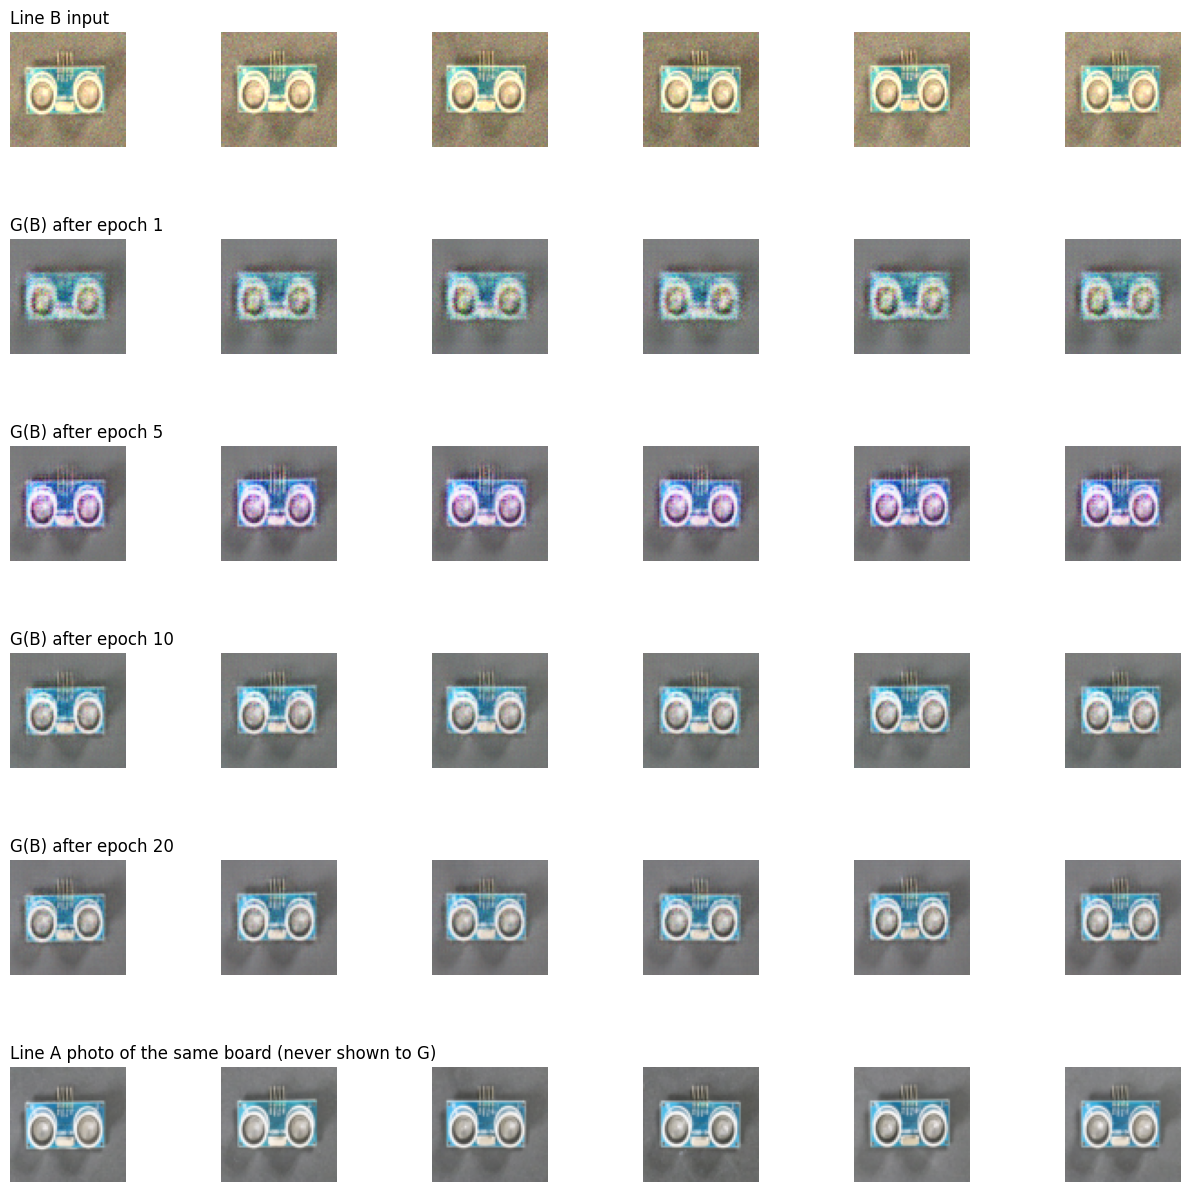

In [27]:
show = sorted({e for e in [1, EPOCHS_GAN // 4, EPOCHS_GAN // 2, EPOCHS_GAN] if e in snaps})
fig, ax = plt.subplots(len(show) + 2, 6, figsize=(12, 2.1 * (len(show) + 2)))
for i in range(6):
    ax[0, i].imshow(X["test_ok_B"][i].permute(1, 2, 0)); ax[-1, i].imshow(X["test_ok"][i].permute(1, 2, 0))
    for r, e in enumerate(show, start=1):
        ax[r, i].imshow(snaps[e][i].permute(1, 2, 0).clamp(0, 1))
    for r in range(len(show) + 2): ax[r, i].axis("off")
ax[0, 0].set_title("Line B input", loc="left"); ax[-1, 0].set_title("Line A photo of the same board (never shown to G)", loc="left")
for r, e in enumerate(show, start=1): ax[r, 0].set_title(f"G(B) after epoch {e}", loc="left")
plt.tight_layout(); plt.savefig("cyclegan_epochs.png", dpi=120); plt.show()

## 4. 轉換後再檢測：過殺下降了嗎？瑕疵還在嗎？
先試**最簡單的方法**：顏色正規化（把 B 線每個顏色通道的平均和標準差，調成 A 線的）。CycleGAN 要比它好才值得用。

In [28]:
mu_A, sd_A = X["A_train"].mean((0, 2, 3), keepdim=True), X["A_train"].std((0, 2, 3), keepdim=True)
mu_B, sd_B = X["B_train"].mean((0, 2, 3), keepdim=True), X["B_train"].std((0, 2, 3), keepdim=True)
def color_norm(x):
    return ((x - mu_B) / sd_B * sd_A + mu_A).clamp(0, 1)

@torch.no_grad()
def b2a(x):
    G.eval()
    return torch.cat([to_01(G(to_pm(xb).to(device))).cpu().clamp(0, 1) for xb in x.split(64)])

rows += [report("B 線 → 顏色正規化", color_norm(X["test_ok_B"]), color_norm(X["bad_B"])),
         report("B 線 → CycleGAN G", b2a(X["test_ok_B"]), b2a(X["bad_B"]))]

B 線 → 顏色正規化                  過殺   8.7% | 漏檢  57.0% | AUROC 0.856
B 線 → CycleGAN G             過殺   0.0% | 漏檢  98.0% | AUROC 0.874


**瑕疵存活檢查**：瑕疵區域（遮罩內）的誤差，是不是還明顯高於其他地方？
比值 ＝ 遮罩內平均誤差 ÷ 遮罩外平均誤差。比值掉到接近 1 → 瑕疵被轉換「抹掉」了。

In [29]:
def defect_ratio(x):
    e = err_map(x)
    return ((e * M_bad).sum((1, 2)) / M_bad.sum((1, 2)).clamp(min=1)) / ((e * ~M_bad).sum((1, 2)) / (~M_bad).sum((1, 2)))

for name, x in [("A 線原圖", X["bad"]), ("B 線直接", X["bad_B"]), ("B → 顏色正規化", color_norm(X["bad_B"])), ("B → CycleGAN", b2a(X["bad_B"]))]:
    r = defect_ratio(x)
    print(f"{name:14s} 瑕疵區誤差 ÷ 其他區：中位數 {r.median():.2f}；比值 < 1.5 的不良品 {(r < 1.5).sum().item():3d} / {len(r)} 張")

A 線原圖          瑕疵區誤差 ÷ 其他區：中位數 5.40；比值 < 1.5 的不良品   4 / 100 張
B 線直接          瑕疵區誤差 ÷ 其他區：中位數 1.54；比值 < 1.5 的不良品  44 / 100 張
B → 顏色正規化      瑕疵區誤差 ÷ 其他區：中位數 2.44；比值 < 1.5 的不良品  21 / 100 張
B → CycleGAN   瑕疵區誤差 ÷ 其他區：中位數 2.35；比值 < 1.5 的不良品  27 / 100 張


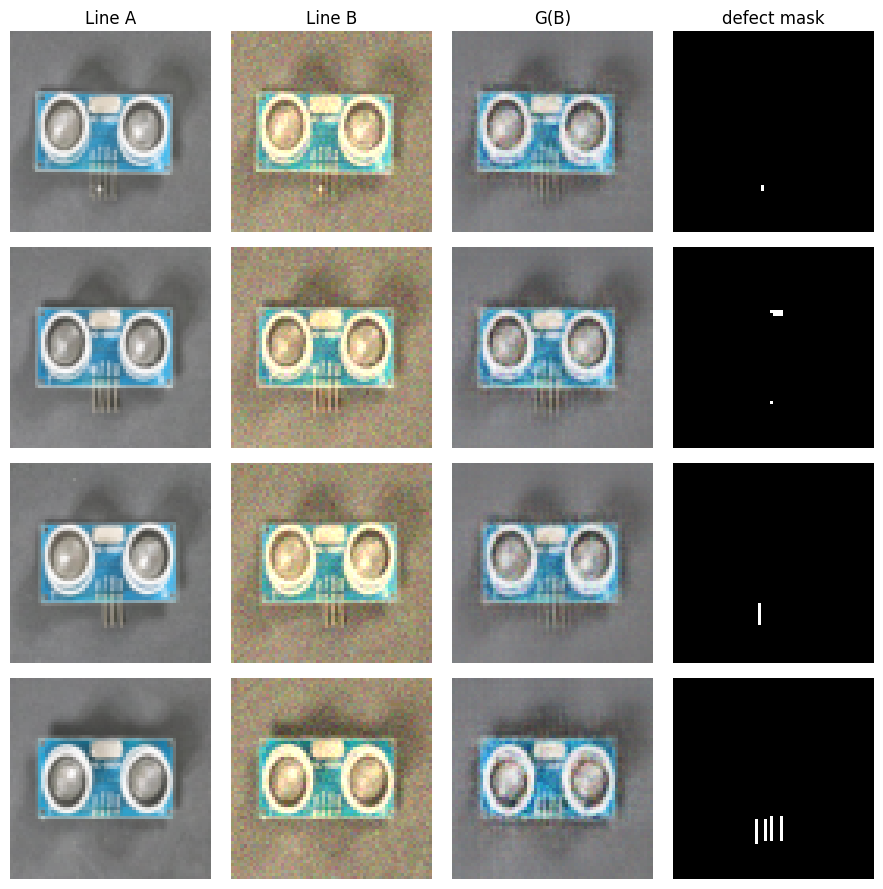

In [30]:
idx = defect_ratio(b2a(X["bad_B"])).argsort()[:4]          # 被轉換傷害最大的 4 張
fig, ax = plt.subplots(4, 4, figsize=(9, 9))
gb = b2a(X["bad_B"][idx])
for r, i in enumerate(idx):
    for c, (img, t) in enumerate([(X["bad"][i], "Line A"), (X["bad_B"][i], "Line B"), (gb[r], "G(B)"), (M_bad[i].float(), "defect mask")]):
        ax[r, c].imshow(img.permute(1, 2, 0) if img.dim() == 3 else img, cmap=None if img.dim() == 3 else "gray")
        ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(t)
plt.tight_layout(); plt.savefig("defect_survival.png", dpi=120); plt.show()

## 5. 交給 B 線品保的一頁
把上面的對照表抄進投影片「Lab 7／7」。要回答三件事：
1. B 線直接用 A 線模型，過殺是多少？
2. 顏色正規化和 CycleGAN，哪一個把過殺降得比較多？漏檢有沒有變差？
3. 有沒有不良品的瑕疵在轉換後「不見了」？（看 `defect_survival.png`）